# Demand Forecasting Analysis


step 1 imports 

In [1]:
# standard imports
import pandas as pd 
import numpy as np
import matplotlib.pyplot as pit
import seaborn as sns 
import matplotlib.pyplot as plt

# sklearn 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

#Models 
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBRegressor 

# metrics & utilities 
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

#Display setting
sns.set_theme(style="whitegrid", palette="muted", font_scale=1.05)
pd.set_option("display.max_columns", 200)
plt.rcParams["figure.figsize"] = (10, 6)

Step 2. Load the Data 

In [2]:
# Load dataset (adjust path if neended)
df = pd.read_csv("data.csv")
print("Shape:", df.shape)
df.head()

Shape: (1048575, 5)


,Product_Code,Warehouse,Product_Category,Date,Order_Demand
0,Product_0993,Whse_J,Category_028,2012/7/27,100
1,Product_0979,Whse_J,Category_028,2012/1/19,500
2,Product_0979,Whse_J,Category_028,2012/2/3,500
3,Product_0979,Whse_J,Category_028,2012/2/9,500
4,Product_0979,Whse_J,Category_028,2012/3/2,500


Step 3.Initial Inspection

In [3]:
#dataset Overview 
print ("=" * 50)
print ("DATASET INFORMATION")
print ("=" * 50)

#Basic Information
print("\nStatistical Summary:")
display (df.info ())

#Stastical Summary
print("\nStatistical Summary:")
display (df.describe(include="all").T)

#Missing Value Check
print ("\n" + "=" * 50)
print ("Missing Values")
print ("=" * 50)
display (df.isnull().sum())

#Duplicate Recordsn Check 
print("\n" + "=" * 50)
print("Duplicate Rows")
print("=" * 50)
print("Total Duplicate Rows:", df.duplicated().sum())


DATASET INFORMATION

Statistical Summary:
<class 'pandas.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 5 columns):
 #   Column            Non-Null Count    Dtype
---  ------            --------------    -----
 0   Product_Code      1048575 non-null  str  
 1   Warehouse         1048575 non-null  str  
 2   Product_Category  1048575 non-null  str  
 3   Date              1037336 non-null  str  
 4   Order_Demand      1048575 non-null  str  
dtypes: str(5)
memory usage: 40.0 MB


None


Statistical Summary:


,count,unique,top,freq
Product_Code,1048575,2160,Product_1359,16936
Warehouse,1048575,4,Whse_J,764447
Product_Category,1048575,33,Category_019,481099
Date,1037336,1729,2013/9/27,2075
Order_Demand,1048575,3828,1000,112682



Missing Values


Product_Code            0
Warehouse               0
Product_Category        0
Date                11239
Order_Demand            0
dtype: int64


Duplicate Rows
Total Duplicate Rows: 122423


Step 4. Data Cleaning

In [4]:
# 1. Clean Date column
df["Date"] = pd.to_datetime(df["Date"], format="%Y/%m/%d", errors="coerce")

# 2. Clean Order_Demand ("(100)" ka matlab -100)
df["Order_Demand"] = (
    df["Order_Demand"]
    .astype(str)
    .str.replace("(", "-", regex=False)
    .str.replace(")", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

# 3. Convert to numeric safely
df["Order_Demand"] = pd.to_numeric(df["Order_Demand"], errors="coerce")

# 4. Remove invalid rows (Date ya demand missing)
df = df.dropna(subset=["Date", "Order_Demand"])

# 5. Sort by time and reset index
df = df.sort_values(by="Date").reset_index(drop=True)

# Final check
print("Cleaned Dataset Shape:", df.shape)
print("\nMissing values after cleaning:\n", df.isnull().sum())
df.head()



Cleaned Dataset Shape: (1037336, 5)

Missing values after cleaning:
 Product_Code        0
Warehouse           0
Product_Category    0
Date                0
Order_Demand        0
dtype: int64


,Product_Code,Warehouse,Product_Category,Date,Order_Demand
0,Product_0965,Whse_A,Category_006,2011-01-08,2
1,Product_1724,Whse_A,Category_003,2011-05-31,108
2,Product_1521,Whse_S,Category_019,2011-06-24,85000
3,Product_1521,Whse_S,Category_019,2011-06-24,7000
4,Product_1507,Whse_C,Category_019,2011-09-02,1250


Step 5. Exploratory Data Analysis (Visualizations)

Dataset Shape: (1037336, 5)


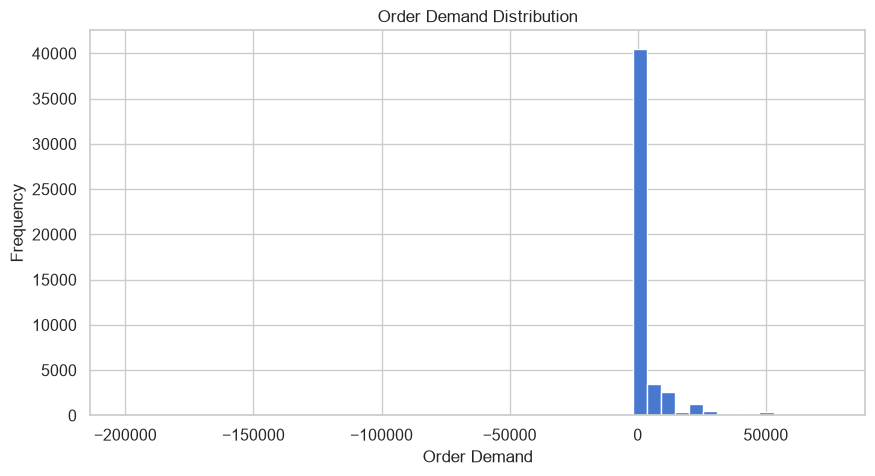

In [5]:
print ("Dataset Shape:", df.shape)

#1. Order Demand Distribution
plt.figure(figsize=(10, 5))

# Sample data for better performance and  visualization
sample_data = df["Order_Demand"].sample(50000, random_state=42) 

#Limit to 99th percentage to remove extreme outliners 
upper_limit = sample_data.quantile(0.99)
sample_data = sample_data[sample_data <= upper_limit]

# Plot histogram 
plt.hist(sample_data, bins=50)

# Tiles and Lables  
plt.title("Order Demand Distribution")
plt.xlabel("Order Demand")
plt.ylabel("Frequency")

plt.show()



ValueError: supplied range of [-inf, 15.201805169084134] is not finite

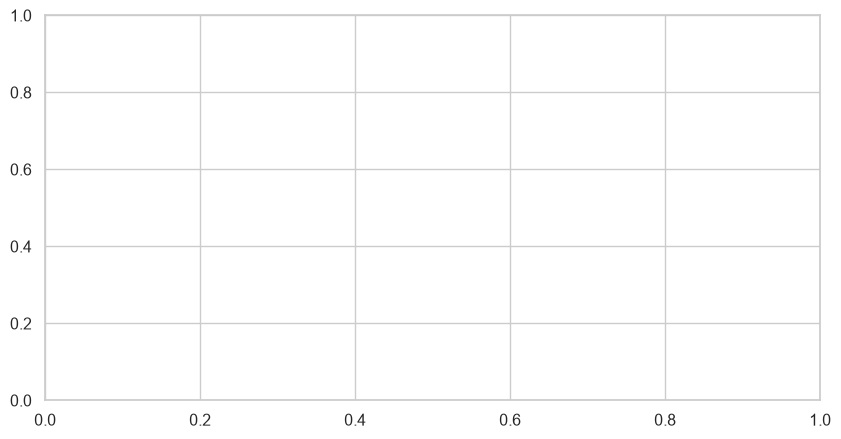

In [6]:
# 2. log Transformation Plot 
plt.figure(figsize=(10, 5))
log_demand = np.log1p(df["Order_Demand"])
plt.hist(log_demand, bins=50)
plt.title("Log Transforemed Order Demand Distribution")
plt.xlabel("Log (Order Demand)")
plt.ylabel("Frequency")
plt.show()

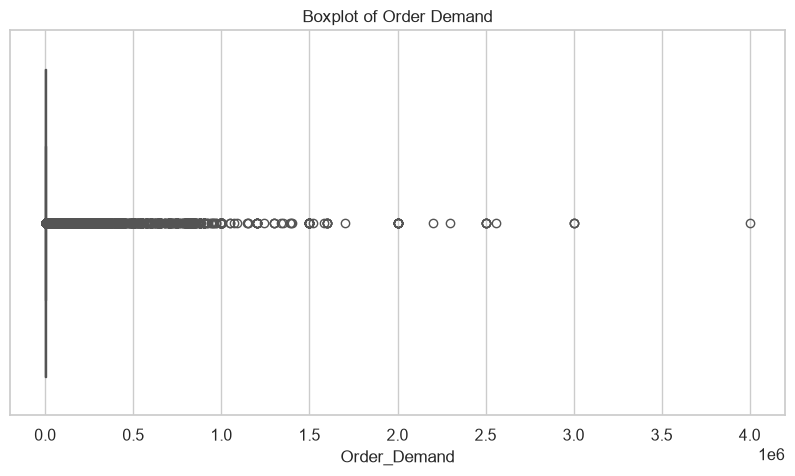

In [ ]:
# 3. Boxplot for Outlier Detection 

plt.figure(figsize=(10,5))
sns.boxplot(x=df["Order_Demand"])
plt.title("Boxplot of Order Demand")
plt.show()

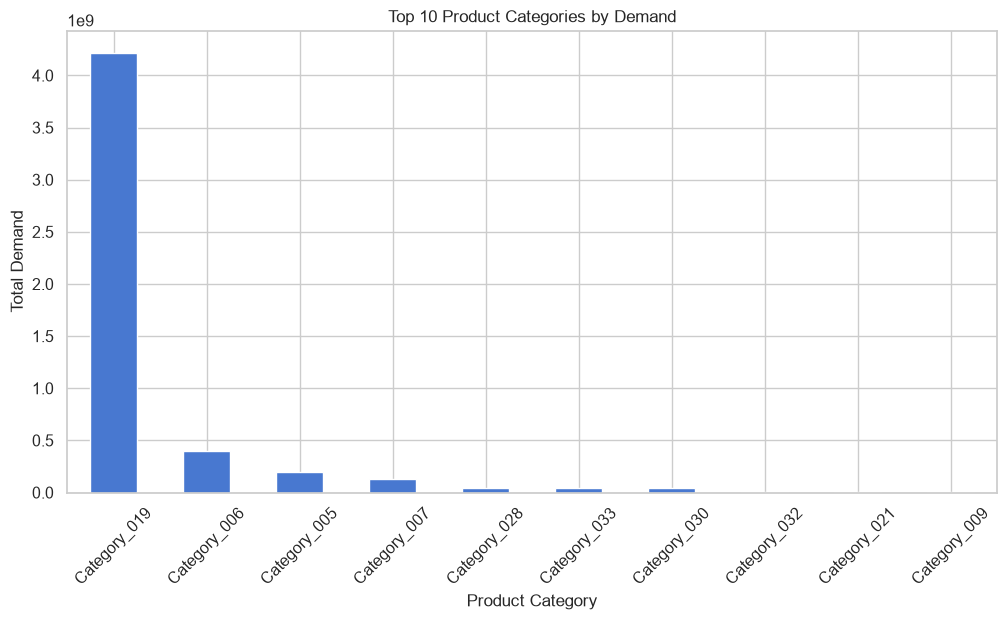

In [ ]:
# 4. product category-wise Demand 

category_demand = df.groupby("Product_Category")["Order_Demand"].sum().sort_values(ascending=False)

plt.figure(figsize=(12,6))
category_demand.head(10).plot(kind="bar")
plt.title("Top 10 Product Categories by Demand")
plt.xlabel("Product Category")
plt.ylabel("Total Demand")
plt.xticks(rotation=45)
plt.show()

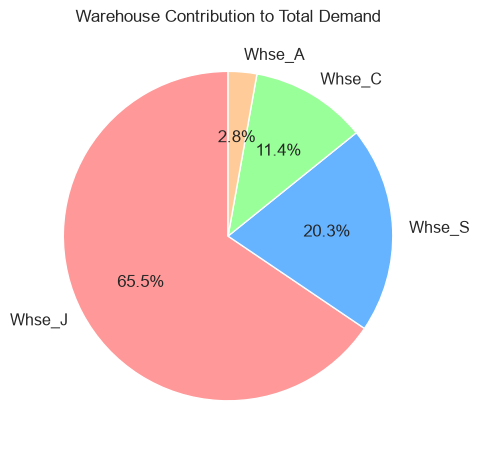

In [ ]:
# 5. Pie Chart of Warehouse Share

warehouse_demand = df.groupby("Warehouse")["Order_Demand"].sum().sort_values(ascending=False)
plt.figure(figsize=(5, 5))

warehouse_demand.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90,
    colors=["#ff9999", "#66b3ff", "#99ff99", "#ffcc99"]
)

plt.title("Warehouse Contribution to Total Demand")
plt.ylabel("")
plt.tight_layout()
plt.show()

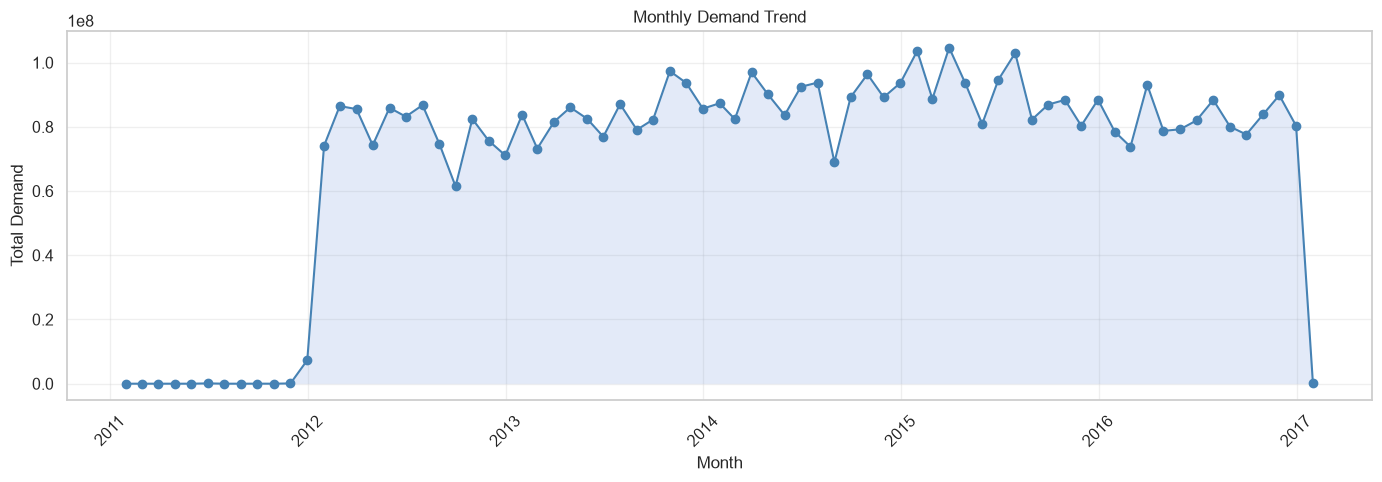

In [ ]:
# 6. Monthly Demand Trend
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

monthly = df.resample("ME", on="Date")["Order_Demand"].sum()

plt.figure(figsize=(14, 5))
plt.plot(monthly.index, monthly.values, marker="o", color="steelblue")
plt.fill_between(monthly.index, monthly.values, alpha=0.15)

plt.title("Monthly Demand Trend")
plt.xlabel("Month")
plt.ylabel("Total Demand")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

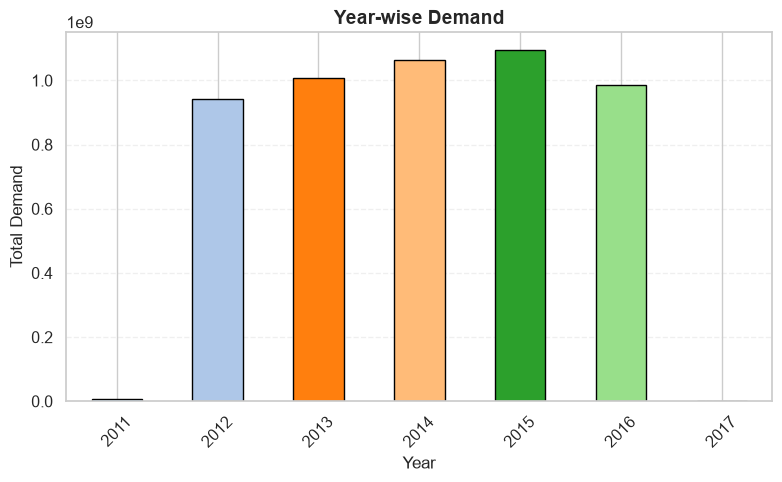

In [ ]:
# 7. Year-Wise Demand
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Create Year column (FIX)
df["Year"] = df["Date"].dt.year

# Group by Year
yearly_demand = df.groupby("Year")["Order_Demand"].sum()
plt.figure(figsize=(8, 5))

# Distinct colors
colors = plt.cm.tab20(range(len(yearly_demand)))

yearly_demand.plot(
    kind="bar",
    color=colors,
    edgecolor="black"
)

plt.title("Year-wise Demand", fontsize=14, fontweight="bold")
plt.xlabel("Year", fontsize=12)
plt.ylabel("Total Demand", fontsize=12)

plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

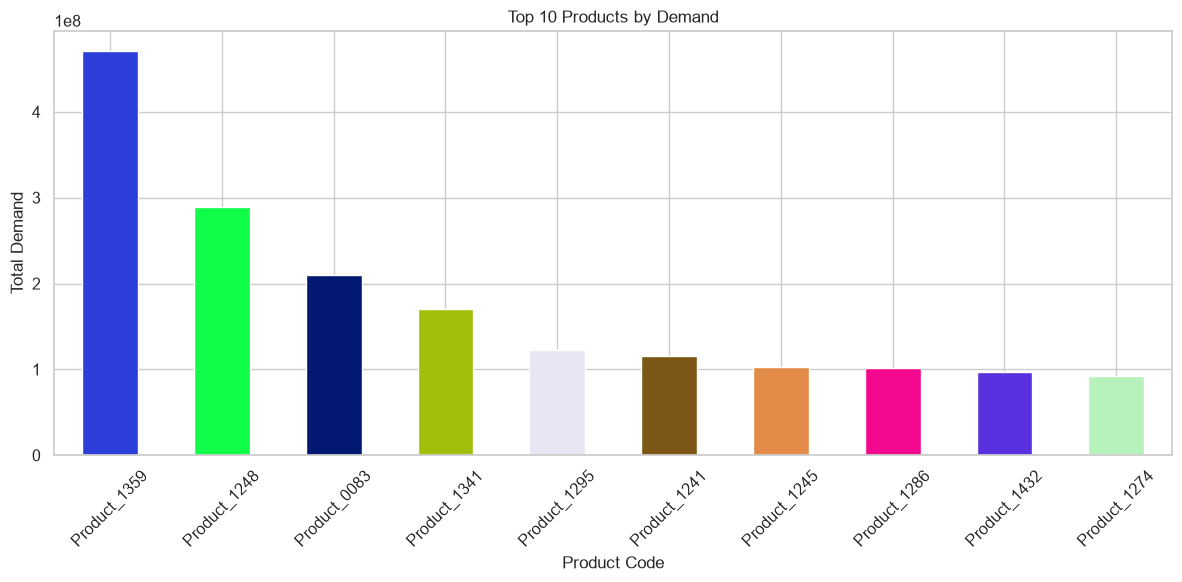

In [ ]:
# 8. Top 10 Products by Demand
top_products = (
    df.groupby("Product_Code")["Order_Demand"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

colors = np.random.rand(len(top_products), 3)

plt.figure(figsize=(12, 6))

top_products.plot(
    kind="bar",
    color=colors
)

plt.title("Top 10 Products by Demand")
plt.xlabel("Product Code")
plt.ylabel("Total Demand")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

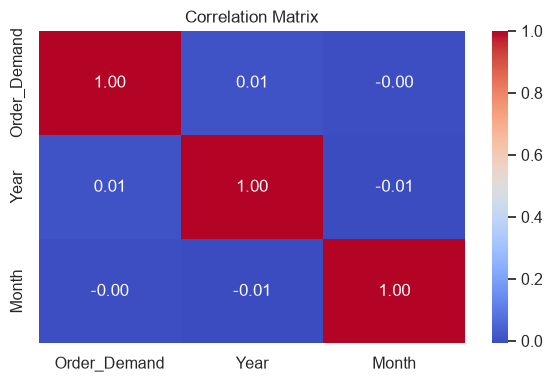

In [ ]:
# 9. Correlation Matrix
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Create missing columns (FIX)
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month

# Select numeric data safely
numeric_df = df[["Order_Demand", "Year", "Month"]]

plt.figure(figsize=(6, 4))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")

plt.tight_layout()
plt.show()

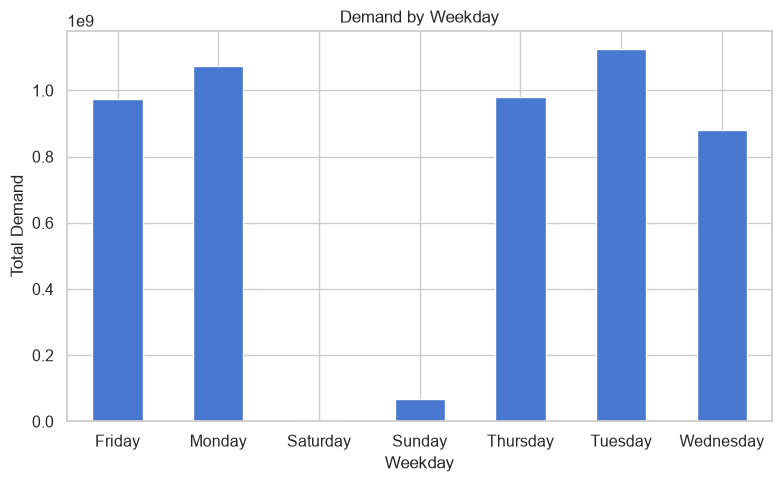

In [ ]:
# 10. Demand by Weekday

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["Weekday"] = df["Date"].dt.day_name()

weekday_demand = df.groupby("Weekday")["Order_Demand"].sum()
plt.figure(figsize=(8, 5))
weekday_demand.plot(kind="bar")

plt.title("Demand by Weekday")

plt.xlabel("Weekday")
plt.ylabel("Total Demand")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

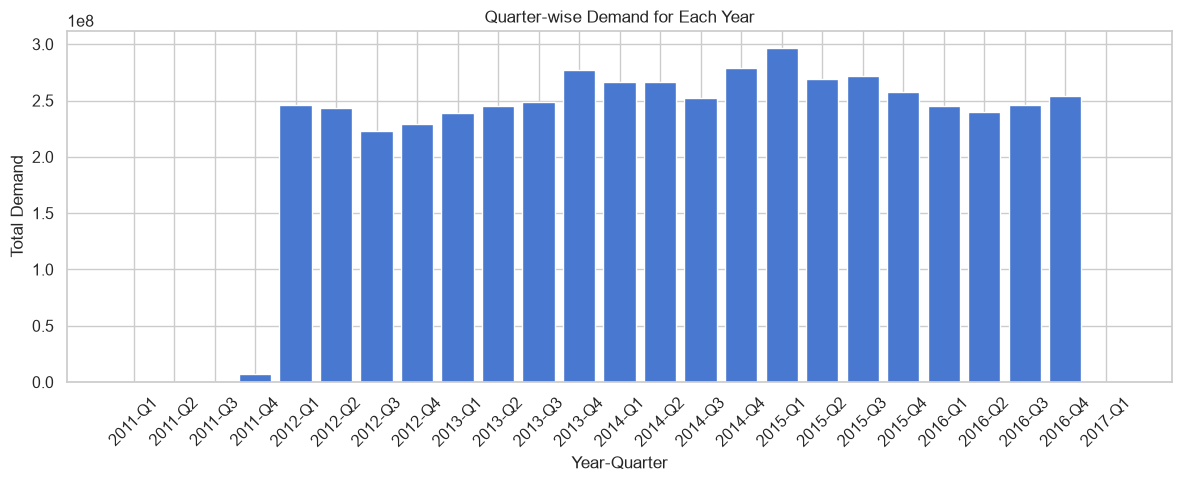

In [ ]:
# 11. Quarter-wise Demand

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

df["Year"] = df["Date"].dt.year
df["Quarter"] = "Q" + df["Date"].dt.quarter.astype(str)

quarter_year_demand = df.groupby(["Year", "Quarter"])["Order_Demand"].sum().reset_index()

# Create label for plotting
quarter_year_demand["Year_Quarter"] = (
    quarter_year_demand["Year"].astype(str) + "-" +
    quarter_year_demand["Quarter"]
)

plt.figure(figsize=(12, 5))

plt.bar(
    quarter_year_demand["Year_Quarter"],
    quarter_year_demand["Order_Demand"]
)

plt.title("Quarter-wise Demand for Each Year")

plt.xlabel("Year-Quarter")
plt.ylabel("Total Demand")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Load
df = pd.read_csv("data.csv")

# Clean Date
df["Date"] = pd.to_datetime(df["Date"], format="%Y/%m/%d", errors="coerce")

# Clean Order_Demand ("(100)" ka matlab -100)
df["Order_Demand"] = (
    df["Order_Demand"]
    .astype(str)
    .str.replace("(", "-", regex=False)
    .str.replace(")", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)
df["Order_Demand"] = pd.to_numeric(df["Order_Demand"], errors="coerce")

# Remove invalid rows, sort, reset index
df = df.dropna(subset=["Date", "Order_Demand"])
df = df.sort_values("Date").reset_index(drop=True)

print("Shape:", df.shape)


Shape: (1037336, 5)


Step 6. feature Engineering

In [ ]:
# 1. Daily total demand banao
daily = df.groupby("Date")["Order_Demand"].sum().reset_index()

# 2. 2011 ka sparse data hata do
daily = daily[daily["Date"] >= "2012-01-01"].sort_values("Date").reset_index(drop=True)

# 3. Time-based features
daily["Year"] = daily["Date"].dt.year
daily["Month"] = daily["Date"].dt.month
daily["Day"] = daily["Date"].dt.day
daily["Weekday"] = daily["Date"].dt.weekday
daily["Quarter"] = daily["Date"].dt.quarter

# 4. Cyclical encoding
daily["Month_sin"] = np.sin(2 * np.pi * daily["Month"] / 12)
daily["Month_cos"] = np.cos(2 * np.pi * daily["Month"] / 12)
daily["Weekday_sin"] = np.sin(2 * np.pi * daily["Weekday"] / 7)
daily["Weekday_cos"] = np.cos(2 * np.pi * daily["Weekday"] / 7)

# 5. Lag features
daily["lag_1"] = daily["Order_Demand"].shift(1)
daily["lag_7"] = daily["Order_Demand"].shift(7)
daily["lag_30"] = daily["Order_Demand"].shift(30)

# 6. Rolling stats (shift(1) pehle, taaki aaj ki value use na ho)
daily["rolling_mean_7"] = daily["Order_Demand"].shift(1).rolling(7).mean()
daily["rolling_std_7"] = daily["Order_Demand"].shift(1).rolling(7).std()

# 7. Lag se bani khaali rows hatao
daily = daily.dropna().reset_index(drop=True)



Step 7. Encoding Categorical Features

In [ ]:
for col in ["Product_Code", "Warehouse", "Product_Category"]:
    df[col] = df[col].astype("category").cat.codes

Step 8. Model Preparation

In [ ]:
# Split Data into Training and Testing Sets

daily = df.sort_values("Date")

split_index = int(len(df) * 0.8)

train = df.iloc[:split_index]
test = df.iloc[split_index:]

X_train = train.drop(columns=["Order_Demand", "Date"])
y_train = train["Order_Demand"]

X_test = test.drop(columns=["Order_Demand", "Date"])
y_test = test["Order_Demand"]

print(X_train.shape, X_test.shape)

(829868, 10) (207468, 10)


Step 9. Multiple Machine Learning Models

In [ ]:
models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=12,
        min_samples_split=10,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=12,
        min_samples_split=10,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42
    )
}

# Model Training and Evaluation
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append([name, mae, rmse, r2])

results_df = pd.DataFrame(results, columns=["Model", "MAE", "RMSE", "R2 Score"])
results_df = results_df.sort_values("RMSE")
results_df

,Model,MAE,RMSE,R2 Score
2,Random Forest,5065.724788,25762.681393,0.291650
3,XGBoost,5552.482910,26472.623746,0.252072
1,Decision Tree,5135.791903,26910.691106,0.227114
0,Linear Regression,7375.977258,30502.877076,0.007005


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

Step 10. Best Model Selection 

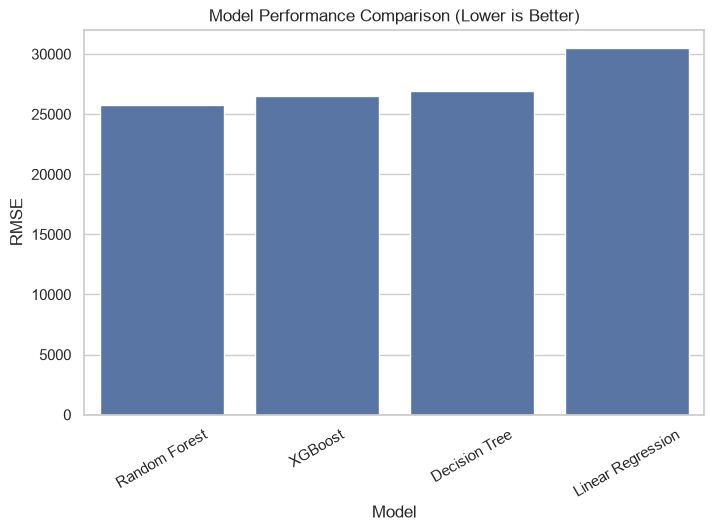

In [ ]:
plt.figure(figsize=(8,5))
sns.barplot(data=results_df, x="Model", y="RMSE")
plt.title("Model Performance Comparison (Lower is Better)")
plt.xticks(rotation=30)
plt.show()

In [ ]:
# Save Best Model Automatically 
import joblib

# Get best model name from result table (lowest RMSE)
best_model_name = results_df.iloc[0]["Model"]

print("Best Model:", best_model_name)

#Get the already trained best model from models dictionary 
best_model = models[best_model_name]

#save the model 
joblib.dump(best_model, "best_demand_forecasting_model.pkl")

print("Best model saved successfully as 'best_demand_forecasting_model.pkl'")

Best Model: Random Forest
Best model saved successfully as 'best_demand_forecasting_model.pkl'
